In [2]:
# ==========================================
# PROJECT INITIALISATION
# ==========================================

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set project root to the parent of the notebooks folder
PROJECT_ROOT = Path.cwd().parent

# Define folders
RAW_DATA = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"

print("Project initialised successfully!")
print("Project root:", PROJECT_ROOT)
print("Processed data folder exists:", PROCESSED_DATA.exists())

Project initialised successfully!
Project root: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics
Processed data folder exists: True


In [3]:
# ==========================================
# LOAD AND INSPECT FINANCIAL REPORTS
# ==========================================

report_files = {
    "Profit and Loss": "profit_and_loss.csv",
    "Balance Sheet": "balance_sheet.csv",
    "Financial Summary": "financial_summary.csv",
    "Budget vs Actual": "budget_vs_actual.csv",
    "Bank Reconciliation": "bank_reconciliation.csv",
    "Exception Register": "exception_register.csv"
}

reports = {}

for report_name, filename in report_files.items():

    file_path = PROCESSED_DATA / filename

    reports[report_name] = pd.read_csv(file_path)

    print(f"\n{report_name}")
    print("-" * 60)
    print("Columns:", reports[report_name].columns.tolist())

    display(reports[report_name].head())


Profit and Loss
------------------------------------------------------------
Columns: ['account_code', 'account_name', 'account_type', 'actual_amount']


,account_code,account_name,account_type,actual_amount
0,5000,Salaries Expense,Expense,30877.97
1,5100,Rent Expense,Expense,6037.88
2,5200,Utilities Expense,Expense,12258.58
3,5300,Software Expense,Expense,11925.84
4,5400,Travel Expense,Expense,7377.40



Balance Sheet
------------------------------------------------------------
Columns: ['account_code', 'total_debit', 'total_credit', 'account_name', 'account_type', 'normal_balance', 'closing_balance', 'presentation_balance', 'statement_section']


,account_code,total_debit,total_credit,account_name,account_type,normal_balance,closing_balance,presentation_balance,statement_section
0,1000,142075.75,62315.92,Bank Account,Asset,Debit,79759.83,79759.83,Assets
1,1100,101413.91,71925.75,Accounts Receivable,Asset,Debit,29488.16,29488.16,Assets
2,1500,8500.00,0.00,Equipment,Asset,Debit,8500.00,8500.00,Assets
3,1590,0.00,250.00,Accumulated Depreciation,Asset,Credit,250.00,-250.00,Assets
4,2000,25814.50,40664.17,Accounts Payable,Liability,Credit,14849.67,14849.67,Liabilities



Financial Summary
------------------------------------------------------------
Columns: ['Metric', 'Budget', 'Actual', 'Variance']


,Metric,Budget,Actual,Variance
0,Revenue,105200,101563.91,-3636.09
1,Expenses,30650,68915.59,-38265.59
2,Net Profit,74550,32648.32,-41901.68


... (2 outputs left out)


Bank Reconciliation
------------------------------------------------------------
Columns: ['transaction_id', 'description', 'gl_amount', 'bank_transaction_id', 'bank_amount', '_merge', 'reconciliation_status', 'duplicate_flag']


,transaction_id,description,gl_amount,bank_transaction_id,bank_amount,_merge,reconciliation_status,duplicate_flag
0,BANKFEE001,Record bank service fee,-45.00,BANK00027,-45.00,both,Matched,False
1,TXN00013,Customer payment - Evergreen Retail Group,6949.91,BANK00001,6949.91,both,Matched,False
2,TXN00014,Customer payment - FutureWorks Ltd.,9276.31,BANK00002,9276.31,both,Matched,False
3,TXN00015,Customer payment - Alpine Consulting,11780.60,NaN,NaN,left_only,Missing from Bank Statement,False
4,TXN00016,Customer payment - Evergreen Retail Group,10074.58,BANK00004,10074.58,both,Matched,False



Exception Register
------------------------------------------------------------
Columns: ['exception_id', 'transaction_id', 'exception_type', 'amount', 'severity', 'status', 'recommended_action']


,exception_id,transaction_id,exception_type,amount,severity,status,recommended_action
0,EXC001,TXN00015,Missing from Bank Statement,11780.60,High,Open,Investigate bank records and confirm whether t...
1,EXC002,TXN00018,Duplicate Bank Transaction,11340.88,High,Open,Verify the duplicate entry and confirm whether...


In [8]:
# ==========================================
# FINANCIAL REPORT CONSISTENCY CHECKS
# ==========================================

# 1. PROFIT & LOSS CHECK
pnl = reports["Profit and Loss"]

pnl_revenue = pnl.loc[
    pnl["account_type"] == "Revenue", "actual_amount"
].sum()

pnl_expenses = pnl.loc[
    pnl["account_type"] == "Expense", "actual_amount"
].sum()

pnl_net_profit = pnl_revenue - pnl_expenses

# 2. FINANCIAL SUMMARY CHECK
summary = reports["Financial Summary"]

summary_revenue = summary.loc[
    summary["Metric"] == "Revenue", "Actual"
].iloc[0]

summary_expenses = summary.loc[
    summary["Metric"] == "Expenses", "Actual"
].iloc[0]

summary_profit = summary.loc[
    summary["Metric"] == "Net Profit", "Actual"
].iloc[0]

# 3. BALANCE SHEET CHECK
bs = reports["Balance Sheet"]

# ==========================================
# CORRECTED BALANCE SHEET QUALITY CHECK
# ==========================================

# Calculate total assets
assets = bs.loc[
    bs["statement_section"] == "Assets",
    "presentation_balance"
].sum()

# Calculate total liabilities
liabilities = bs.loc[
    bs["statement_section"] == "Liabilities",
    "presentation_balance"
].sum()

# Calculate recorded equity
recorded_equity = bs.loc[
    bs["statement_section"] == "Equity",
    "presentation_balance"
].sum()

# Add current-period profit to equity
current_period_profit = pnl_net_profit

total_equity = recorded_equity + current_period_profit

# Calculate accounting equation difference
balance_sheet_difference = (
    assets - liabilities - total_equity
)

print("CORRECTED BALANCE SHEET VALIDATION")
print("=" * 55)

print(f"Total Assets:             €{assets:,.2f}")
print(f"Total Liabilities:        €{liabilities:,.2f}")
print(f"Recorded Equity:          €{recorded_equity:,.2f}")
print(f"Current Period Profit:    €{current_period_profit:,.2f}")
print(f"Total Equity:             €{total_equity:,.2f}")

print("-" * 55)

print(
    f"Liabilities + Equity:     "
    f"€{liabilities + total_equity:,.2f}"
)

print(f"Balance Sheet Difference: €{balance_sheet_difference:,.2f}")

if abs(balance_sheet_difference) <= 0.01:
    print("\nPASS: Balance Sheet balances.")
else:
    print("\nINVESTIGATE: Balance Sheet does not balance.")

CORRECTED BALANCE SHEET VALIDATION
Total Assets:             €117,497.99
Total Liabilities:        €34,849.67
Recorded Equity:          €50,000.00
Current Period Profit:    €32,648.32
Total Equity:             €82,648.32
-------------------------------------------------------
Liabilities + Equity:     €117,497.99
Balance Sheet Difference: €0.00

PASS: Balance Sheet balances.


In [9]:
balance_sheet_difference = assets - liabilities - (
    equity + pnl_net_profit
)

In [10]:
qa_report.to_csv(
    PROCESSED_DATA / "financial_quality_assurance.csv",
    index=False
)

In [11]:
# Inspect existing equity accounts in the Balance Sheet
equity_rows = bs.loc[
    bs["statement_section"] == "Equity"
]

display(equity_rows)

,account_code,total_debit,total_credit,account_name,account_type,normal_balance,closing_balance,presentation_balance,statement_section
6,3000,0.0,50000.0,Share Capital,Equity,Credit,50000.0,50000.0,Equity


In [12]:
# Remove any previous presentation adjustment to avoid duplication
bs = bs[
    bs["account_code"].astype(str) != "CURRENT_PERIOD_PROFIT"
].copy()

# Create the Current Period Profit presentation row
profit_row = {
    "account_code": "CURRENT_PERIOD_PROFIT",
    "total_debit": 0.00,
    "total_credit": 0.00,
    "account_name": "Current Period Profit",
    "account_type": "Equity",
    "normal_balance": "Credit",
    "closing_balance": pnl_net_profit,
    "presentation_balance": pnl_net_profit,
    "statement_section": "Equity"
}

# Add the new row
bs = pd.concat(
    [bs, pd.DataFrame([profit_row])],
    ignore_index=True
)

# Display the updated Equity section
display(
    bs.loc[bs["statement_section"] == "Equity"]
)

,account_code,total_debit,total_credit,account_name,account_type,normal_balance,closing_balance,presentation_balance,statement_section
6,3000,0.0,50000.0,Share Capital,Equity,Credit,50000.00,50000.00,Equity
7,CURRENT_PERIOD_PROFIT,0.0,0.0,Current Period Profit,Equity,Credit,32648.32,32648.32,Equity


In [13]:
# Save the updated Balance Sheet
balance_sheet_path = PROCESSED_DATA / "balance_sheet.csv"

bs.to_csv(balance_sheet_path, index=False)

print("Balance Sheet successfully updated!")
print(f"Saved to: {balance_sheet_path}")
print(f"Total rows: {len(bs)}")

Balance Sheet successfully updated!
Saved to: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\balance_sheet.csv
Total rows: 8


In [14]:
# Reload the saved file rather than relying on the in-memory DataFrame
bs_check = pd.read_csv(balance_sheet_path)

assets = bs_check.loc[
    bs_check["statement_section"] == "Assets",
    "presentation_balance"
].sum()

liabilities = bs_check.loc[
    bs_check["statement_section"] == "Liabilities",
    "presentation_balance"
].sum()

equity = bs_check.loc[
    bs_check["statement_section"] == "Equity",
    "presentation_balance"
].sum()

difference = assets - liabilities - equity

print("EXPORTED BALANCE SHEET VALIDATION")
print("=" * 45)
print(f"Total Assets:       €{assets:,.2f}")
print(f"Total Liabilities:  €{liabilities:,.2f}")
print(f"Total Equity:       €{equity:,.2f}")
print(f"Liabilities + Equity: €{liabilities + equity:,.2f}")
print(f"Difference:         €{difference:,.2f}")

print("\nPASS: Exported Balance Sheet balances."
      if abs(difference) < 0.01
      else "\nFAIL: Investigate Balance Sheet.")

EXPORTED BALANCE SHEET VALIDATION
Total Assets:       €117,497.99
Total Liabilities:  €34,849.67
Total Equity:       €82,648.32
Liabilities + Equity: €117,497.99
Difference:         €0.00

PASS: Exported Balance Sheet balances.


In [15]:
# Reload all reports from disk for final validation
report_files = {
    "Profit and Loss": "profit_and_loss.csv",
    "Balance Sheet": "balance_sheet.csv",
    "Financial Summary": "financial_summary.csv",
    "Budget vs Actual": "budget_vs_actual.csv",
    "Bank Reconciliation": "bank_reconciliation.csv",
    "Exception Register": "exception_register.csv"
}

reports = {}

for report_name, filename in report_files.items():
    file_path = PROCESSED_DATA / filename
    reports[report_name] = pd.read_csv(file_path)

    print(f"Loaded: {report_name} — {len(reports[report_name])} rows")

print("\nAll six reports reloaded successfully.")

Loaded: Profit and Loss — 9 rows
Loaded: Balance Sheet — 8 rows
Loaded: Financial Summary — 3 rows
Loaded: Budget vs Actual — 10 rows
Loaded: Bank Reconciliation — 26 rows
Loaded: Exception Register — 2 rows

All six reports reloaded successfully.


In [16]:
# ==========================================
# FINAL FINANCIAL QUALITY ASSURANCE
# ==========================================

pnl = reports["Profit and Loss"]
bs = reports["Balance Sheet"]
summary = reports["Financial Summary"]
budget = reports["Budget vs Actual"]
reconciliation = reports["Bank Reconciliation"]
exceptions = reports["Exception Register"]

# 1. Profit and Loss validation
pnl_revenue = pnl.loc[
    pnl["account_type"] == "Revenue", "actual_amount"
].sum()

pnl_expenses = pnl.loc[
    pnl["account_type"] == "Expense", "actual_amount"
].sum()

pnl_profit = pnl_revenue - pnl_expenses

summary_revenue = summary.loc[
    summary["Metric"] == "Revenue", "Actual"
].iloc[0]

summary_expenses = summary.loc[
    summary["Metric"] == "Expenses", "Actual"
].iloc[0]

summary_profit = summary.loc[
    summary["Metric"] == "Net Profit", "Actual"
].iloc[0]

# 2. Balance Sheet validation
assets = bs.loc[
    bs["statement_section"] == "Assets",
    "presentation_balance"
].sum()

liabilities = bs.loc[
    bs["statement_section"] == "Liabilities",
    "presentation_balance"
].sum()

equity = bs.loc[
    bs["statement_section"] == "Equity",
    "presentation_balance"
].sum()

bs_difference = assets - liabilities - equity

# 3. Budget vs Actual validation
budget_revenue = budget.loc[
    budget["category"] == "Revenue", "actual_amount"
].sum()

budget_expenses = budget.loc[
    budget["category"] == "Expense", "actual_amount"
].sum()

# 4. Reconciliation and exception validation
open_exceptions = exceptions.loc[
    exceptions["status"] == "Open"
]

reconciliation_exception_count = (
    reconciliation["reconciliation_status"]
    .isin([
        "Missing from Bank Statement",
        "Not Recorded in General Ledger",
        "Amount Mismatch"
    ]).sum()
    + reconciliation["duplicate_flag"].fillna(False).astype(bool).sum()
)

# 5. Create QA results
qa_results = [
    ("P&L revenue agrees with financial summary",
     abs(pnl_revenue - summary_revenue)),

    ("P&L expenses agree with financial summary",
     abs(pnl_expenses - summary_expenses)),

    ("P&L net profit agrees with financial summary",
     abs(pnl_profit - summary_profit)),

    ("Balance Sheet accounting equation",
     abs(bs_difference)),

    ("Budget actual revenue agrees with summary",
     abs(budget_revenue - summary_revenue)),

    ("Budget actual expenses agree with summary",
     abs(budget_expenses - summary_expenses)),

    ("Open exceptions agree with exception register",
     abs(len(open_exceptions) - len(exceptions))),

    ("Bank reconciliation exceptions count",
     abs(reconciliation_exception_count - len(exceptions)))
]

qa_report = pd.DataFrame(
    qa_results,
    columns=["Quality Check", "Difference"]
)

qa_report["Status"] = np.where(
    qa_report["Difference"] < 0.01,
    "PASS",
    "INVESTIGATE"
)

display(qa_report)

print("\nFINAL QA SUMMARY")
print("=" * 45)
print(f"Checks performed: {len(qa_report)}")
print(f"Passed: {(qa_report['Status'] == 'PASS').sum()}")
print(f"Investigate: {(qa_report['Status'] == 'INVESTIGATE').sum()}")

,Quality Check,Difference,Status
0,P&L revenue agrees with financial summary,0.000000e+00,PASS
1,P&L expenses agree with financial summary,0.000000e+00,PASS
2,P&L net profit agrees with financial summary,7.275958e-12,PASS
3,Balance Sheet accounting equation,0.000000e+00,PASS
4,Budget actual revenue agrees with summary,0.000000e+00,PASS
5,Budget actual expenses agree with summary,0.000000e+00,PASS
6,Open exceptions agree with exception register,0.000000e+00,PASS
7,Bank reconciliation exceptions count,0.000000e+00,PASS



FINAL QA SUMMARY
Checks performed: 8
Passed: 8
Investigate: 0


In [17]:
# Save final financial quality assurance report
qa_path = PROCESSED_DATA / "financial_quality_assurance.csv"

qa_report.to_csv(qa_path, index=False)

print("FINAL QA REPORT SAVED")
print("=" * 40)
print(f"File: {qa_path}")
print(f"Checks performed: {len(qa_report)}")
print(f"Passed: {(qa_report['Status'] == 'PASS').sum()}")
print(f"Investigate: {(qa_report['Status'] == 'INVESTIGATE').sum()}")

FINAL QA REPORT SAVED
File: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\data\processed\financial_quality_assurance.csv
Checks performed: 8
Passed: 8
Investigate: 0


In [18]:
# ==========================================
# MANAGEMENT REPORT: EXECUTIVE SUMMARY
# ==========================================

# Load the saved financial reports
financial_summary = pd.read_csv(
    PROCESSED_DATA / "financial_summary.csv"
)

profit_loss = pd.read_csv(
    PROCESSED_DATA / "profit_and_loss.csv"
)

# Display the financial summary
print("NORTHSTAR GLOBAL SERVICES LTD.")
print("FINANCIAL PERFORMANCE — NOVEMBER 2026")
print("=" * 55)

display(financial_summary)

# Display the detailed Profit and Loss statement
print("\nPROFIT AND LOSS DETAILS")
print("=" * 55)

display(profit_loss)

NORTHSTAR GLOBAL SERVICES LTD.
FINANCIAL PERFORMANCE — NOVEMBER 2026


,Metric,Budget,Actual,Variance
0,Revenue,105200,101563.91,-3636.09
1,Expenses,30650,68915.59,-38265.59
2,Net Profit,74550,32648.32,-41901.68



PROFIT AND LOSS DETAILS


,account_code,account_name,account_type,actual_amount
0,5000,Salaries Expense,Expense,30877.97
1,5100,Rent Expense,Expense,6037.88
2,5200,Utilities Expense,Expense,12258.58
3,5300,Software Expense,Expense,11925.84
4,5400,Travel Expense,Expense,7377.40
5,5500,Depreciation Expense,Expense,250.00
6,5600,Bank Charges,Expense,187.92
7,4000,Service Revenue,Revenue,101413.91
8,4100,Interest Income,Revenue,150.00


# Executive Summary
**Northstar Global Services Ltd.**  
**Reporting Period: November 2026**  
**Currency: EUR**

Northstar Global Services Ltd. generated total revenue of **€101,563.91** during November 2026, against a budget of €105,200. This represents an adverse revenue variance of **€3,636.09 (3.46%)**.

Total operating expenses and other expenses amounted to **€68,915.59**, compared with a budget of €30,650. Expenses therefore exceeded the approved budget by **€38,265.59**. This significant overspend was the main contributor to the company's financial performance falling below expectations.

Despite the expenditure overrun, the company remained profitable, recording a net profit of **€32,648.32**, equivalent to a net profit margin of approximately **32.14%**. However, this was €41,901.68 below the budgeted net profit of €74,550, representing an adverse variance of approximately 56.21%.

The results indicate that revenue performance was relatively close to budget, while expenditure control requires considerably more attention. Management should prioritise reviewing personnel costs, utilities, software and travel expenditure to understand the drivers of the significant variances and determine whether they are recurring, exceptional, or attributable to budgeting assumptions.

Overall, Northstar remained profitable in November 2026, but the gap between budgeted and actual profitability highlights the need for stronger expenditure monitoring and more effective budgetary control.

In [19]:
# ==========================================
# EXECUTIVE SUMMARY KPIs
# ==========================================

revenue_budget = financial_summary.loc[
    financial_summary["Metric"] == "Revenue", "Budget"
].iloc[0]

revenue_actual = financial_summary.loc[
    financial_summary["Metric"] == "Revenue", "Actual"
].iloc[0]

expenses_budget = financial_summary.loc[
    financial_summary["Metric"] == "Expenses", "Budget"
].iloc[0]

expenses_actual = financial_summary.loc[
    financial_summary["Metric"] == "Expenses", "Actual"
].iloc[0]

profit_budget = financial_summary.loc[
    financial_summary["Metric"] == "Net Profit", "Budget"
].iloc[0]

profit_actual = financial_summary.loc[
    financial_summary["Metric"] == "Net Profit", "Actual"
].iloc[0]

# Calculate performance indicators
revenue_variance_pct = (
    (revenue_actual - revenue_budget) / revenue_budget
) * 100

expense_variance_pct = (
    (expenses_actual - expenses_budget) / expenses_budget
) * 100

profit_variance_pct = (
    (profit_actual - profit_budget) / profit_budget
) * 100

net_profit_margin = (profit_actual / revenue_actual) * 100

# Create KPI table
executive_kpis = pd.DataFrame({
    "KPI": [
        "Revenue",
        "Expenses",
        "Net Profit",
        "Net Profit Margin"
    ],
    "Budget": [
        revenue_budget,
        expenses_budget,
        profit_budget,
        np.nan
    ],
    "Actual": [
        revenue_actual,
        expenses_actual,
        profit_actual,
        net_profit_margin
    ],
    "Variance_Percentage": [
        revenue_variance_pct,
        expense_variance_pct,
        profit_variance_pct,
        np.nan
    ]
})

display(executive_kpis.round(2))

,KPI,Budget,Actual,Variance_Percentage
0,Revenue,105200.0,101563.91,-3.46
1,Expenses,30650.0,68915.59,124.85
2,Net Profit,74550.0,32648.32,-56.21
3,Net Profit Margin,NaN,32.15,NaN


In [20]:
# ==========================================
# TOP THREE EXPENSE OVERRUNS
# ==========================================

budget_analysis = pd.read_csv(
    PROCESSED_DATA / "budget_vs_actual.csv"
)

# Select expense categories
expense_analysis = budget_analysis[
    budget_analysis["category"] == "Expense"
].copy()

# Calculate overspending
expense_analysis["overspend"] = (
    expense_analysis["actual_amount"]
    - expense_analysis["budget_amount"]
)

# Keep only categories exceeding budget
expense_overruns = expense_analysis[
    expense_analysis["overspend"] > 0
].copy()

# Rank by largest overspend
expense_overruns = expense_overruns.sort_values(
    by="overspend",
    ascending=False
)

# Display top three
top_three_overruns = expense_overruns[
    [
        "account_name",
        "budget_amount",
        "actual_amount",
        "overspend",
        "variance_percentage"
    ]
].head(3)

display(top_three_overruns.round(2))

,account_name,budget_amount,actual_amount,overspend,variance_percentage
4,Utilities Expense,1000,12258.58,11258.58,-1125.86
5,Software Expense,1200,11925.84,10725.84,-893.82
2,Salaries Expense,22000,30877.97,8877.97,-40.35


### Expense Performance and Budgetary Control

The company's total expenses exceeded the November 2026 budget by **€38,265.59**. Three categories accounted for approximately **80.65%** of this overspend.

**Utilities Expense** recorded the largest adverse variance, with actual expenditure of €12,258.58 against a budget of €1,000. This resulted in an overspend of €11,258.58.

**Software Expense** recorded actual expenditure of €11,925.84 against a budget of €1,200, producing an adverse variance of €10,725.84.

**Salaries Expense** amounted to €30,877.97 compared with a budget of €22,000, resulting in an overspend of €8,877.97.

Management should investigate the underlying drivers of these variances, review the assumptions used in preparing the budget, and strengthen expenditure monitoring. Particular attention should be given to utility consumption and billing, software subscription management, and payroll cost controls.

In [21]:
# ==========================================
# BANK RECONCILIATION EXCEPTIONS
# ==========================================

exceptions = pd.read_csv(
    PROCESSED_DATA / "exception_register.csv"
)

display(
    exceptions[
        [
            "exception_id",
            "transaction_id",
            "exception_type",
            "amount",
            "severity",
            "status",
            "recommended_action"
        ]
    ]
)

,exception_id,transaction_id,exception_type,amount,severity,status,recommended_action
0,EXC001,TXN00015,Missing from Bank Statement,11780.60,High,Open,Investigate bank records and confirm whether t...
1,EXC002,TXN00018,Duplicate Bank Transaction,11340.88,High,Open,Verify the duplicate entry and confirm whether...


### Bank Reconciliation and Outstanding Exceptions

The November 2026 bank reconciliation identified two unresolved exceptions, both classified as high severity.

The first exception, TXN00015, relates to a general ledger transaction of **€11,780.60** that could not be matched to the bank statement. The finance team should investigate the transaction date, payment status, bank records and supporting documentation to determine whether the item represents an outstanding transaction, a timing difference or an omission.

The second exception, TXN00018, relates to a potentially duplicated bank transaction amounting to **€11,340.88**. The finance team should compare the bank statement entries with the original transaction reference and supporting records to establish whether the duplicate is genuine.

The combined value of the two flagged transactions is **€23,121.48**. This amount represents the value of transactions requiring investigation and should not be interpreted as a confirmed financial loss.

Both exceptions remain open. Management should assign responsibility for their investigation, retain supporting evidence and ensure that the exception register is updated when the matters are resolved.

In [22]:
# ==========================================
# MONTH-END CONTROL REVIEW
# ==========================================

control_summary = pd.read_csv(
    PROCESSED_DATA / "month_end_control_summary.csv"
)

display(control_summary)

,Control,Result,Status
0,Journal entries reviewed,52,Pass
1,Unbalanced journal entries,0,Pass
2,Unexpected journal line counts,0,Pass
3,Duplicate journal lines,0,Pass
4,Invalid account codes,0,Pass
5,Transactions outside reporting period,0,Pass
6,Open bank reconciliation exceptions,2,Open
7,High-severity open exceptions,2,Open


### Internal Controls and Month-End Close Assessment

The month-end control review covered 52 journal entries for November 2026. All six journal and transaction validation controls passed.

No unbalanced journal entries, unexpected journal line counts, duplicate journal lines, invalid account codes or transactions outside the reporting period were identified.

However, the bank reconciliation control identified two outstanding high-severity exceptions. These relate to a transaction missing from the bank statement and a potentially duplicated bank transaction, with a combined flagged value of €23,121.48.

Although the journal and transaction validation checks were satisfactory, the reconciliation exceptions require further investigation. Management should ensure that both items are assigned to responsible finance personnel, supported by appropriate documentation and resolved through the established month-end control process.

The results demonstrate that the simulated month-end process includes key validation and exception-monitoring procedures. However, the open reconciliation items mean that the close should be treated as having outstanding follow-up actions rather than being fully cleared.

In [23]:
# ==========================================
# MANAGEMENT REPORT KPI SUMMARY
# ==========================================

management_kpis = pd.DataFrame({
    "Indicator": [
        "Total Revenue",
        "Total Expenses",
        "Net Profit",
        "Net Profit Margin",
        "Revenue Budget Variance (%)",
        "Expense Budget Variance (%)",
        "Net Profit Budget Variance (%)",
        "Open Reconciliation Exceptions",
        "Total Flagged Transaction Value",
        "Journal Entries Reviewed"
    ],
    "Value": [
        revenue_actual,
        expenses_actual,
        profit_actual,
        net_profit_margin,
        revenue_variance_pct,
        expense_variance_pct,
        profit_variance_pct,
        len(open_exceptions),
        exceptions.loc[
            exceptions["status"] == "Open", "amount"
        ].sum(),
        52
    ]
})

display(management_kpis.round(2))

# Save consolidated KPI table
management_kpis.to_csv(
    PROCESSED_DATA / "management_kpi_summary.csv",
    index=False
)

print("\nManagement KPI summary saved successfully.")

,Indicator,Value
0,Total Revenue,101563.91
1,Total Expenses,68915.59
2,Net Profit,32648.32
3,Net Profit Margin,32.15
4,Revenue Budget Variance (%),-3.46
5,Expense Budget Variance (%),124.85
6,Net Profit Budget Variance (%),-56.21
7,Open Reconciliation Exceptions,2.00
8,Total Flagged Transaction Value,23121.48
9,Journal Entries Reviewed,52.00



Management KPI summary saved successfully.


# NORTHSTAR GLOBAL SERVICES LTD.
## Monthly Financial Management Report

**Reporting period:** November 2026  
**Reporting currency:** EUR  
**Report classification:** Synthetic portfolio case study

---

## 1. Executive Summary

Northstar Global Services Ltd. generated total revenue of **€101,563.91** during November 2026, compared with a budget of €105,200. This represents an adverse revenue variance of €3,636.09 (3.46%).

Total expenses amounted to **€68,915.59**, against a budget of €30,650, resulting in an overspend of €38,265.59 (124.85% above budget).

Despite the expenditure overrun, the company remained profitable, recording a net profit of **€32,648.32**, equivalent to a net profit margin of **32.15%**. However, actual net profit was €41,901.68 below the budgeted profit of €74,550, representing an adverse variance of 56.21%.

The results indicate that revenue performance was relatively close to budget, while expenditure control requires significant management attention. Utilities, software and salaries were the three largest contributors to the expense overspend.

The bank reconciliation process also identified two unresolved high-severity exceptions with a combined flagged transaction value of €23,121.48.

Overall, the company remained profitable, but the financial results highlight the importance of stronger expenditure monitoring, timely reconciliation and effective month-end controls.

## 2. Financial Performance

| Indicator | Budget (€) | Actual (€) | Variance |
|---|---:|---:|---:|
| Revenue | 105,200.00 | 101,563.91 | -3.46% |
| Expenses | 30,650.00 | 68,915.59 | +124.85% |
| Net Profit | 74,550.00 | 32,648.32 | -56.21% |

The company achieved a net profit margin of 32.15%.

Revenue consisted of:
- Service Revenue: €101,413.91
- Interest Income: €150.00

The financial results show that the principal challenge during the reporting period was expenditure management rather than a substantial revenue shortfall.

## 3. Expense Analysis and Budgetary Control

Total expenses exceeded the approved budget by €38,265.59.

The three largest expense overruns were:

| Expense category | Budget (€) | Actual (€) | Overspend (€) |
|---|---:|---:|---:|
| Utilities | 1,000.00 | 12,258.58 | 11,258.58 |
| Software | 1,200.00 | 11,925.84 | 10,725.84 |
| Salaries | 22,000.00 | 30,877.97 | 8,877.97 |
| **Total** | **24,200.00** | **55,062.39** | **30,862.39** |

These three categories accounted for approximately 80.65% of the total expense overspend.

### Management recommendations

**Utilities:** Review consumption, billing periods, supplier invoices and unusual charges.

**Software:** Review software subscriptions, licence renewals, unused licences and possible duplicate services.

**Salaries:** Investigate overtime, staffing changes, payroll adjustments and the assumptions used in the original budget.

The underlying causes have not yet been established and require supporting documentation and investigation.

## 4. Bank Reconciliation and Outstanding Exceptions

The November bank reconciliation identified two unresolved high-severity exceptions.

| Exception | Transaction | Description | Amount (€) |
|---|---|---|---:|
| EXC001 | TXN00015 | Missing from bank statement | 11,780.60 |
| EXC002 | TXN00018 | Duplicate bank transaction | 11,340.88 |
| **Total** | | | **23,121.48** |

### Recommended actions

1. Investigate TXN00015 against bank records, payment confirmations and supporting documentation.
2. Verify whether TXN00018 represents a genuine duplicate transaction.
3. Assign responsibility and target resolution dates for both exceptions.
4. Maintain supporting evidence and update the exception register and audit trail when resolved.

The combined flagged amount represents the value of transactions requiring investigation. It is not a confirmed financial loss.

## 5. Internal Controls and Month-End Close

The month-end control review covered 52 journal entries.

The following six controls passed:

- Unbalanced journal entries: 0.
- Unexpected journal line counts: 0.
- Duplicate journal lines: 0.
- Invalid account codes: 0.
- Transactions outside the reporting period: 0.
- Journal entries reviewed: 52.

However, two high-severity bank reconciliation exceptions remain open.

The journal and transaction validation results were satisfactory, but the outstanding bank exceptions require further investigation before all reconciliation matters can be considered resolved.

## 6. Financial Reporting Quality Assurance

Eight cross-report quality-assurance checks were performed.

All eight passed:

- P&L revenue agrees with the financial summary.
- P&L expenses agree with the financial summary.
- P&L net profit agrees with the financial summary.
- Balance Sheet accounting equation balances.
- Budget actual revenue agrees with the financial summary.
- Budget actual expenses agree with the financial summary.
- Open exceptions agree with the exception register.
- Bank reconciliation exception count agrees with the exception register.

The Balance Sheet reported:
- Total Assets: €117,497.99
- Total Liabilities: €34,849.67
- Total Equity: €82,648.32

The accounting equation balances with a difference of €0.00.

These checks establish consistency across the generated reports; they do not independently verify the authenticity of underlying source transactions.

## 7. Management Action Plan

| Priority | Action | Expected outcome |
|---|---|---|
| High | Investigate the missing bank transaction | Establish transaction status |
| High | Verify the potentially duplicated transaction | Confirm whether duplication occurred |
| High | Review utilities expenditure | Identify overspending drivers |
| High | Review software subscriptions | Improve subscription cost control |
| High | Review payroll expenditure | Explain personnel cost variance |
| Medium | Improve monthly budget monitoring | Identify adverse variances earlier |
| Medium | Maintain reconciliation evidence and audit trail | Strengthen accountability |

## 8. Conclusion

Northstar Global Services Ltd. remained profitable in November 2026, generating €32,648.32 in net profit. Nevertheless, the substantial expenditure overrun reduced profitability significantly compared with budget.

The immediate management priorities are to investigate the two outstanding bank reconciliation exceptions, understand the major expense variances and strengthen expenditure monitoring.

The month-end reporting workflow successfully produced a balanced Balance Sheet and consistent financial reports,

In [24]:
# ==========================================
# SAVE MANAGEMENT REPORT
# ==========================================

management_report_path = REPORTS / "november_2026_management_report.md"

print("Management report destination:")
print(management_report_path)

Management report destination:
C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\reports\november_2026_management_report.md


In [25]:

# ==========================================
# SAVE NOVEMBER 2026 MANAGEMENT REPORT
# ==========================================

management_report = """
# NORTHSTAR GLOBAL SERVICES LTD.
## Monthly Financial Management Report

**Reporting period:** November 2026  
**Reporting currency:** EUR  
**Report classification:** Synthetic portfolio case study

---

## 1. Executive Summary

Northstar Global Services Ltd. generated total revenue of **€101,563.91** during November 2026, compared with a budget of €105,200. This represents an adverse revenue variance of €3,636.09 (3.46%).

Total expenses amounted to **€68,915.59**, against a budget of €30,650, resulting in an overspend of €38,265.59 (124.85% above budget).

Despite the expenditure overrun, the company remained profitable, recording a net profit of **€32,648.32**, equivalent to a net profit margin of **32.15%**. However, actual net profit was €41,901.68 below the budgeted profit of €74,550.

The results indicate that revenue performance was relatively close to budget, while expenditure control requires significant management attention.

## 2. Financial Performance

| Indicator | Budget (€) | Actual (€) | Variance |
|---|---:|---:|---:|
| Revenue | 105,200.00 | 101,563.91 | -3.46% |
| Expenses | 30,650.00 | 68,915.59 | +124.85% |
| Net Profit | 74,550.00 | 32,648.32 | -56.21% |

Revenue consisted of:
- Service Revenue: €101,413.91
- Interest Income: €150.00

Net profit margin was **32.15%**.

## 3. Expense Analysis and Budgetary Control

Total expenses exceeded the approved budget by €38,265.59.

The three largest expense overruns were:

| Expense category | Budget (€) | Actual (€) | Overspend (€) |
|---|---:|---:|---:|
| Utilities | 1,000.00 | 12,258.58 | 11,258.58 |
| Software | 1,200.00 | 11,925.84 | 10,725.84 |
| Salaries | 22,000.00 | 30,877.97 | 8,877.97 |
| **Total** | **24,200.00** | **55,062.39** | **30,862.39** |

These categories accounted for approximately **80.65%** of the total expense overspend.

### Management recommendations

- **Utilities:** Review consumption, billing periods, supplier invoices and unusual charges.
- **Software:** Review subscriptions, licence renewals, unused licences and possible duplicate services.
- **Salaries:** Investigate overtime, staffing changes, payroll adjustments and budget assumptions.

The underlying causes have not yet been established and require investigation.

## 4. Bank Reconciliation and Outstanding Exceptions

The November bank reconciliation identified two unresolved high-severity exceptions.

| Exception | Transaction | Description | Amount (€) |
|---|---|---|---:|
| EXC001 | TXN00015 | Missing from bank statement | 11,780.60 |
| EXC002 | TXN00018 | Duplicate bank transaction | 11,340.88 |
| **Total** | | | **23,121.48** |

### Recommended actions

1. Investigate TXN00015 against bank records, payment confirmations and supporting documentation.
2. Verify whether TXN00018 represents a genuine duplicate transaction.
3. Assign responsibility and target resolution dates for both exceptions.
4. Retain supporting evidence and update the exception register and audit trail when resolved.

The combined flagged amount represents the value of transactions requiring investigation. It is not a confirmed financial loss.

## 5. Internal Controls and Month-End Close

The month-end control review covered 52 journal entries.

The following six journal and transaction validation controls passed:

- Unbalanced journal entries: 0.
- Unexpected journal line counts: 0.
- Duplicate journal lines: 0.
- Invalid account codes: 0.
- Transactions outside the reporting period: 0.
- Journal entries reviewed: 52.

However, two high-severity bank reconciliation exceptions remain open.

The journal and transaction validation results were satisfactory, but the outstanding bank exceptions require further investigation before all reconciliation matters can be considered resolved.

## 6. Financial Reporting Quality Assurance

Eight cross-report quality-assurance checks were performed. All eight passed.

The checks covered:

1. P&L revenue against the financial summary.
2. P&L expenses against the financial summary.
3. P&L net profit against the financial summary.
4. Balance Sheet accounting equation.
5. Budget actual revenue against the financial summary.
6. Budget actual expenses against the financial summary.
7. Open exceptions against the exception register.
8. Bank reconciliation exception count against the exception register.

The Balance Sheet reported:

| Balance Sheet item | Amount (€) |
|---|---:|
| Total Assets | 117,497.99 |
| Total Liabilities | 34,849.67 |
| Total Equity | 82,648.32 |
| Difference | 0.00 |

These checks establish consistency across the generated reports; they do not independently verify the authenticity of underlying source transactions.

## 7. Management Action Plan

| Priority | Action | Expected outcome |
|---|---|---|
| High | Investigate missing bank transaction | Establish transaction status |
| High | Verify potentially duplicated transaction | Confirm whether duplication occurred |
| High | Review utilities expenditure | Identify overspending drivers |
| High | Review software subscriptions | Improve subscription cost control |
| High | Review payroll expenditure | Explain personnel cost variance |
| Medium | Improve monthly budget monitoring | Identify adverse variances earlier |
| Medium | Maintain reconciliation evidence and audit trail | Strengthen accountability |

## 8. Conclusion

Northstar Global Services Ltd. remained profitable in November 2026, generating €32,648.32 in net profit. Nevertheless, the substantial expenditure overrun reduced profitability significantly compared with budget.

The immediate management priorities are to investigate the two outstanding bank reconciliation exceptions, understand the major expense variances and strengthen expenditure monitoring.

The month-end reporting workflow successfully produced a balanced Balance Sheet and consistent financial reports, with all eight defined quality-assurance checks passing.

---

**Prepared as a synthetic Record-to-Report portfolio project.**

**Technology:** Python, pandas, NumPy, Matplotlib and CSV-based financial reporting.

**Reporting period:** November 2026.
"""

# Save the report
management_report_path = (
    REPORTS / "november_2026_management_report.md"
)

management_report_path.write_text(
    management_report.strip(),
    encoding="utf-8"
)

print("MANAGEMENT REPORT SAVED SUCCESSFULLY")
print("=" * 50)
print(f"File: {management_report_path}")
print(f"Characters: {len(management_report)}")
print(f"File exists: {management_report_path.exists()}")


MANAGEMENT REPORT SAVED SUCCESSFULLY
File: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\reports\november_2026_management_report.md
Characters: 6114
File exists: True


In [26]:
# Read the saved report
saved_report = management_report_path.read_text(
    encoding="utf-8"
)

print(saved_report[:1500])
print("\n...")
print("Report successfully verified.")

# NORTHSTAR GLOBAL SERVICES LTD.
## Monthly Financial Management Report

**Reporting period:** November 2026  
**Reporting currency:** EUR  
**Report classification:** Synthetic portfolio case study

---

## 1. Executive Summary

Northstar Global Services Ltd. generated total revenue of **€101,563.91** during November 2026, compared with a budget of €105,200. This represents an adverse revenue variance of €3,636.09 (3.46%).

Total expenses amounted to **€68,915.59**, against a budget of €30,650, resulting in an overspend of €38,265.59 (124.85% above budget).

Despite the expenditure overrun, the company remained profitable, recording a net profit of **€32,648.32**, equivalent to a net profit margin of **32.15%**. However, actual net profit was €41,901.68 below the budgeted profit of €74,550.

The results indicate that revenue performance was relatively close to budget, while expenditure control requires significant management attention.

## 2. Financial Performance

| Indicator | Budge

In [27]:
# Check whether ReportLab is installed

try:
    import reportlab
    print("ReportLab is installed.")
    print("Version:", reportlab.Version)

except ImportError:
    print("ReportLab is not installed.")
    print("Run: %pip install reportlab")

ReportLab is not installed.
Run: %pip install reportlab


In [28]:
%pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.0 MB 500.4 kB/s eta 0:00:03
   --------------- ------------------------ 0.8/2.0 MB 641.2 kB/s eta 0:00:02
   -------------------- ------------------- 1.0/2.0 MB 771.5 kB/s eta 0:00:02
   ------------------------- -------------- 1.3/2.0 MB 824.8 kB/s eta 0:00:01
   ------------------------------- -------- 1.6/2.0 MB 902.6 kB/s eta 0:00:01
   ------------------------------------ --- 1.8/2.0 MB 942.9 kB/s eta 0:00:01
   ---------------------------------------- 2.0/2.0 MB 946.5 kB/s  0:00:02
Note: you may need to restart the kernel to use updated packages.


In [29]:
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    HRFlowable
)
from reportlab.lib.units import cm

print("ReportLab imported successfully.")
print("Management report exists:", management_report_path.exists())
print("Report size:", management_report_path.stat().st_size, "characters")

ReportLab imported successfully.
Management report exists: True
Report size: 6296 characters


In [30]:
report_text = management_report_path.read_text(encoding="utf-8")

print("REPORT PREVIEW")
print("=" * 70)
print(report_text[:2500])

print("\nREPORT LENGTH:", len(report_text), "characters")

REPORT PREVIEW
# NORTHSTAR GLOBAL SERVICES LTD.
## Monthly Financial Management Report

**Reporting period:** November 2026  
**Reporting currency:** EUR  
**Report classification:** Synthetic portfolio case study

---

## 1. Executive Summary

Northstar Global Services Ltd. generated total revenue of **€101,563.91** during November 2026, compared with a budget of €105,200. This represents an adverse revenue variance of €3,636.09 (3.46%).

Total expenses amounted to **€68,915.59**, against a budget of €30,650, resulting in an overspend of €38,265.59 (124.85% above budget).

Despite the expenditure overrun, the company remained profitable, recording a net profit of **€32,648.32**, equivalent to a net profit margin of **32.15%**. However, actual net profit was €41,901.68 below the budgeted profit of €74,550.

The results indicate that revenue performance was relatively close to budget, while expenditure control requires significant management attention.

## 2. Financial Performance

| In

In [31]:
lines = report_text.splitlines()

print("REPORT SECTIONS")
print("=" * 50)

for line in lines:
    if line.startswith("#"):
        print(line)

table_count = sum(
    1 for line in lines
    if line.strip().startswith("|")
)

print("\nMarkdown table lines:", table_count)
print("Total lines:", len(lines))

REPORT SECTIONS
# NORTHSTAR GLOBAL SERVICES LTD.
## Monthly Financial Management Report
## 1. Executive Summary
## 2. Financial Performance
## 3. Expense Analysis and Budgetary Control
### Management recommendations
## 4. Bank Reconciliation and Outstanding Exceptions
### Recommended actions
## 5. Internal Controls and Month-End Close
## 6. Financial Reporting Quality Assurance
## 7. Management Action Plan
## 8. Conclusion

Markdown table lines: 31
Total lines: 145


In [32]:
import re
from xml.sax.saxutils import escape

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, HRFlowable
)

# --------------------------------------------------
# 1. OUTPUT FILE
# --------------------------------------------------

pdf_path = REPORTS / "november_2026_management_report.pdf"

# --------------------------------------------------
# 2. DOCUMENT STYLES
# --------------------------------------------------

styles = getSampleStyleSheet()

styles.add(ParagraphStyle(
    name="CompanyTitle",
    parent=styles["Title"],
    fontName="Helvetica-Bold",
    fontSize=19,
    leading=24,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=8
))

styles.add(ParagraphStyle(
    name="ReportSubtitle",
    parent=styles["Normal"],
    fontSize=13,
    leading=18,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#526579"),
    spaceAfter=18
))

styles.add(ParagraphStyle(
    name="SectionHeading",
    parent=styles["Heading2"],
    fontName="Helvetica-Bold",
    fontSize=13,
    leading=17,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=13,
    spaceAfter=7,
    keepWithNext=True
))

styles.add(ParagraphStyle(
    name="SubHeading",
    parent=styles["Heading3"],
    fontSize=10.5,
    leading=14,
    textColor=colors.HexColor("#365F91"),
    spaceBefore=9,
    spaceAfter=5,
    keepWithNext=True
))

styles.add(ParagraphStyle(
    name="ReportBody",
    parent=styles["BodyText"],
    fontName="Helvetica",
    fontSize=9,
    leading=14,
    alignment=TA_LEFT,
    spaceAfter=7
))

styles.add(ParagraphStyle(
    name="ReportBullet",
    parent=styles["ReportBody"],
    leftIndent=15,
    firstLineIndent=-9,
    spaceAfter=5
))

styles.add(ParagraphStyle(
    name="TableText",
    parent=styles["ReportBody"],
    fontSize=7.5,
    leading=10,
    spaceAfter=0
))

styles.add(ParagraphStyle(
    name="TableHeader",
    parent=styles["TableText"],
    fontName="Helvetica-Bold",
    textColor=colors.white
))

# --------------------------------------------------
# 3. MARKDOWN INLINE FORMATTING
# --------------------------------------------------

def format_inline(text):
    text = escape(text.strip())
    text = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", text)
    text = re.sub(r"\*(.+?)\*", r"<i>\1</i>", text)
    return text

# --------------------------------------------------
# 4. PDF PAGE HEADER AND FOOTER
# --------------------------------------------------

def add_page_details(canvas, doc):
    canvas.saveState()

    page_width, page_height = A4

    if doc.page > 1:
        canvas.setFont("Helvetica", 8)
        canvas.setFillColor(colors.HexColor("#526579"))
        canvas.drawString(
            2 * cm,
            page_height - 1.2 * cm,
            "NORTHSTAR GLOBAL SERVICES LTD. | NOVEMBER 2026"
        )
        canvas.setStrokeColor(colors.HexColor("#D9E2F3"))
        canvas.line(
            2 * cm, page_height - 1.4 * cm,
            page_width - 2 * cm, page_height - 1.4 * cm
        )

    canvas.setStrokeColor(colors.HexColor("#D9E2F3"))
    canvas.line(
        2 * cm, 1.5 * cm,
        page_width - 2 * cm, 1.5 * cm
    )

    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#526579"))
    canvas.drawString(
        2 * cm, 1.0 * cm,
        "Synthetic Portfolio Case Study"
    )
    canvas.drawRightString(
        page_width - 2 * cm, 1.0 * cm,
        f"Page {doc.page}"
    )

    canvas.restoreState()

# --------------------------------------------------
# 5. BUILD THE REPORT CONTENT
# --------------------------------------------------

story = []
lines = report_text.splitlines()

i = 0
first_title_seen = False

while i < len(lines):
    line = lines[i].strip()

    if not line:
        i += 1
        continue

    # Main company title
    if line.startswith("# "):
        story.append(Paragraph(
            format_inline(line[2:]),
            styles["CompanyTitle"]
        ))
        story.append(HRFlowable(
            width="65%",
            thickness=1.2,
            color=colors.HexColor("#4472C4"),
            hAlign="CENTER",
            spaceAfter=10
        ))
        first_title_seen = True
        i += 1
        continue

    # Report subtitle
    if line.startswith("## ") and "Monthly Financial Management Report" in line:
        story.append(Paragraph(
            format_inline(line[3:]),
            styles["ReportSubtitle"]
        ))
        i += 1
        continue

    # Section headings
    if line.startswith("## "):
        story.append(Paragraph(
            format_inline(line[3:]),
            styles["SectionHeading"]
        ))
        i += 1
        continue

    # Subheadings
    if line.startswith("### "):
        story.append(Paragraph(
            format_inline(line[4:]),
            styles["SubHeading"]
        ))
        i += 1
        continue

    # Horizontal rule
    if line == "---":
        story.append(Spacer(1, 4))
        story.append(HRFlowable(
            width="100%",
            thickness=0.5,
            color=colors.HexColor("#D9E2F3"),
            spaceAfter=8
        ))
        i += 1
        continue

    # Markdown tables
    if line.startswith("|"):
        table_lines = []

        while i < len(lines) and lines[i].strip().startswith("|"):
            current = lines[i].strip()
            cells = [
                cell.strip()
                for cell in current.strip("|").split("|")
            ]

            # Ignore Markdown separator rows
            if not all(
                re.fullmatch(r":?-{3,}:?", cell.replace(" ", ""))
                for cell in cells
            ):
                table_lines.append(cells)

            i += 1

        if table_lines:
            table_data = []

            for row_index, row in enumerate(table_lines):
                formatted_row = []

                for cell in row:
                    style = (
                        styles["TableHeader"]
                        if row_index == 0
                        else styles["TableText"]
                    )
                    formatted_row.append(
                        Paragraph(format_inline(cell), style)
                    )

                table_data.append(formatted_row)

            column_count = max(len(row) for row in table_data)
            available_width = A4[0] - 4 * cm
            col_width = available_width / column_count

            pdf_table = Table(
                table_data,
                colWidths=[col_width] * column_count,
                repeatRows=1,
                hAlign="LEFT"
            )

            pdf_table.setStyle(TableStyle([
                ("BACKGROUND", (0, 0), (-1, 0),
                 colors.HexColor("#17365D")),
                ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
                ("GRID", (0, 0), (-1, -1), 0.35,
                 colors.HexColor("#D9E2F3")),
                ("VALIGN", (0, 0), (-1, -1), "TOP"),
                ("LEFTPADDING", (0, 0), (-1, -1), 5),
                ("RIGHTPADDING", (0, 0), (-1, -1), 5),
                ("TOPPADDING", (0, 0), (-1, -1), 5),
                ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
                ("ROWBACKGROUNDS", (0, 1), (-1, -1),
                 [colors.white, colors.HexColor("#F3F6FA")])
            ]))

            story.append(pdf_table)
            story.append(Spacer(1, 9))

        continue

    # Bullet points
    if line.startswith("- "):
        story.append(Paragraph(
            "• " + format_inline(line[2:]),
            styles["ReportBullet"]
        ))
        i += 1
        continue

    # Ordinary paragraphs
    story.append(Paragraph(
        format_inline(line),
        styles["ReportBody"]
    ))
    i += 1

# --------------------------------------------------
# 6. CREATE THE PDF
# --------------------------------------------------

document = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=2 * cm,
    leftMargin=2 * cm,
    topMargin=2.2 * cm,
    bottomMargin=2 * cm,
    title="November 2026 Monthly Financial Management Report",
    author="Northstar Global Services Ltd. - Synthetic Portfolio Case Study"
)

document.build(
    story,
    onFirstPage=add_page_details,
    onLaterPages=add_page_details
)

print("PDF GENERATED SUCCESSFULLY")
print("=" * 50)
print("File:", pdf_path)
print("File exists:", pdf_path.exists())
print("File size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

PDF GENERATED SUCCESSFULLY
File: C:\Users\hp\Desktop\Gdansk University of Technology, Poland\Job\AON\Project\finance-rtr-analytics\reports\november_2026_management_report.pdf
File exists: True
File size: 10.0 KB


In [34]:
%pip install pypdf

Note: you may need to restart the kernel to use updated packages.


In [35]:
from pypdf import PdfReader

reader = PdfReader(str(pdf_path))

print("PDF QUALITY CHECK")
print("=" * 50)
print("Number of pages:", len(reader.pages))

for page_number, page in enumerate(reader.pages, start=1):
    page_text = page.extract_text() or ""

    print(f"\nPAGE {page_number}")
    print("Characters:", len(page_text))
    print("Preview:", page_text[:350].replace("\n", " "))

PDF QUALITY CHECK
Number of pages: 4

PAGE 1
Characters: 1580
Preview: Synthetic Portfolio Case Study Page 1  NORTHSTAR GLOBAL SERVICES LTD.  Monthly Financial Management Report Reporting period: November 2026 Reporting currency: EUR Report classification: Synthetic portfolio case study 1. Executive Summary Northstar Global Services Ltd. generated total revenue of €101,563.91 during November 2026, compared with a budg

PAGE 2
Characters: 2002
Preview: NORTHSTAR GLOBAL SERVICES LTD. | NOVEMBER 2026 Synthetic Portfolio Case Study Page 2 These categories accounted for approximately 80.65% of the total expense overspend. Management recommendations   Utilities: Review consumption, billing periods, supplier invoices and unusual charges.   Software: Review subscriptions, licence renewals, unused lice

PAGE 3
Characters: 1736
Preview: NORTHSTAR GLOBAL SERVICES LTD. | NOVEMBER 2026 Synthetic Portfolio Case Study Page 3 6. Financial Reporting Quality Assurance Eight cross-report quality-assura

In [36]:
%pip install pymupdf

   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.3/63.0 MB ? eta -:--:--
   ---------------------------------------- 0.8/63.0 MB 2.8 MB/s eta 0:00:22
   - -------------------------------------- 1.8/63.0 MB 3.9 MB/s eta 0:00:16
   - -------------------------------------- 2.9/63.0 MB 4.2 MB/s eta 0:00:15
   -- ------------------------------------- 3.7/63.0 MB 4.4 MB/s eta 0:00:14
   -- ------------------------------------- 4.5/63.0 MB 4.1 MB/s eta 0:00:15
   --- ------------------------------------ 5.0/63.0 MB 3.8 MB/s eta 0:00:16
   --- ------------------------------------ 5.2/63.0 MB 3.5 MB/s eta 0:00:17
   --- ------------------------------------ 5.5/63.0 MB 3.2 MB/s eta 0:00:18
   --- ------------------------------------ 5.8/63.0 MB 3.0 MB/s eta 0:00:20
   --- ------------------------------------ 5.8/63.0 MB 3.0 MB/s eta 0:00:20
   ---- ------------

Page 1


C:\Users\hp\Downloads\Anaconda\Lib\site-packages\fitz\__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


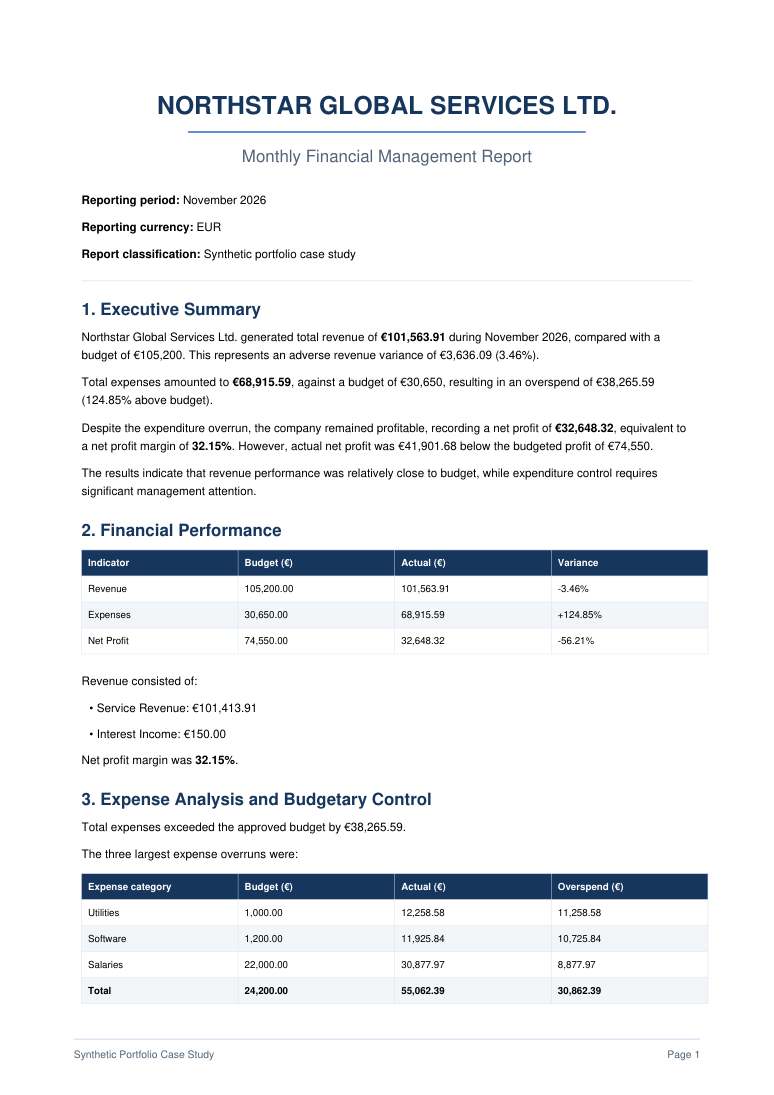

Page 2


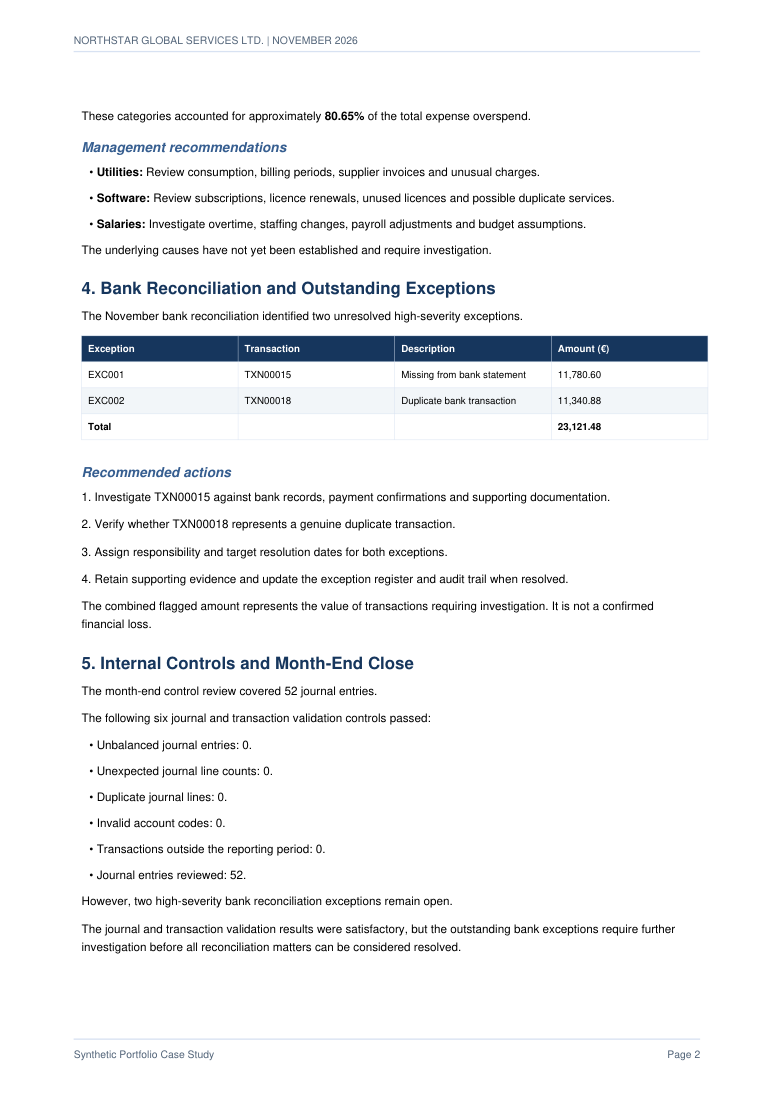

Page 3


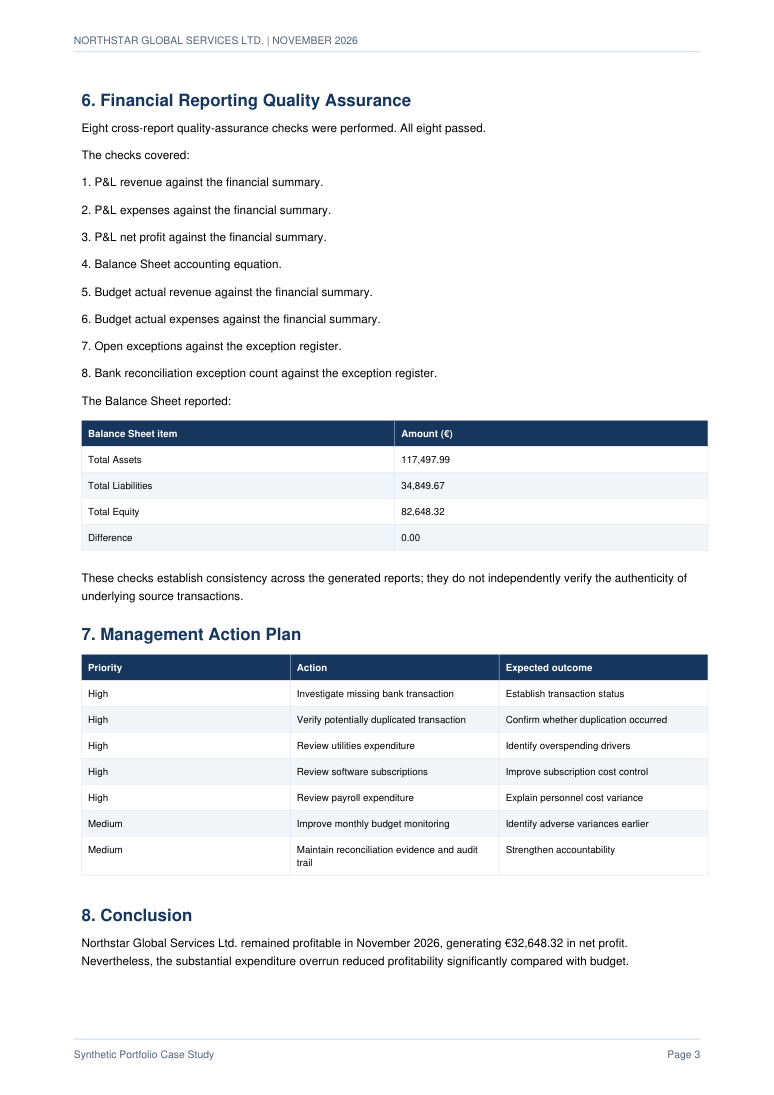

Page 4


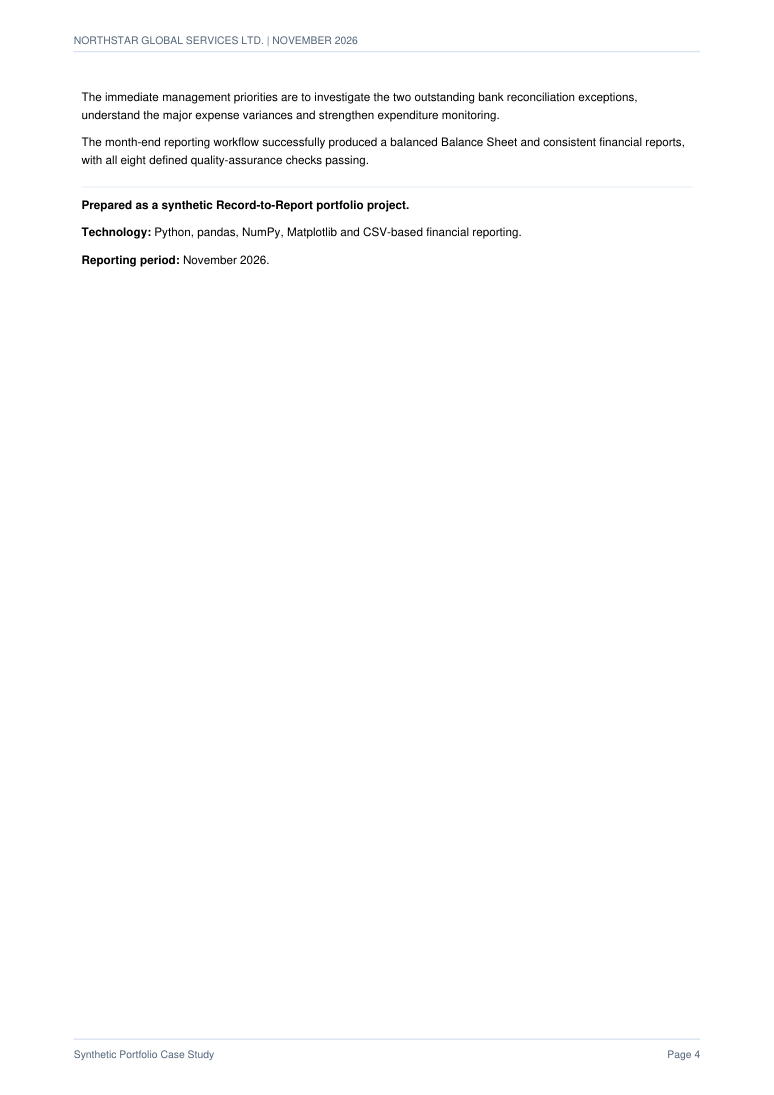

In [37]:
import fitz
from IPython.display import display, Image

pdf_document = fitz.open(str(pdf_path))

for page_number, page in enumerate(pdf_document):
    pix = page.get_pixmap(matrix=fitz.Matrix(1.3, 1.3))
    image_path = REPORTS / f"pdf_preview_page_{page_number + 1}.png"
    pix.save(str(image_path))

    print(f"Page {page_number + 1}")
    display(Image(filename=str(image_path)))

In [38]:
# Reduce paragraph spacing and font size slightly
styles["ReportBody"].fontSize = 8.5
styles["ReportBody"].leading = 12
styles["ReportBody"].spaceAfter = 5

styles["ReportBullet"].fontSize = 8.5
styles["ReportBullet"].leading = 12
styles["ReportBullet"].spaceAfter = 3

styles["SectionHeading"].spaceBefore = 9
styles["SectionHeading"].spaceAfter = 5

styles["SubHeading"].spaceBefore = 6
styles["SubHeading"].spaceAfter = 3

# Reduce padding in existing tables
for item in story:
    if isinstance(item, Table):
        item.setStyle(TableStyle([
            ("TOPPADDING", (0, 0), (-1, -1), 3),
            ("BOTTOMPADDING", (0, 0), (-1, -1), 3)
        ]))

print("PDF layout adjustments applied.")

PDF layout adjustments applied.


In [39]:
from reportlab.platypus import Paragraph

# Replace unsupported bullet symbols with hyphens
clean_story = []

for item in story:
    if isinstance(item, Paragraph):
        clean_text = item.text.replace("• ", "- ")
        clean_story.append(Paragraph(clean_text, item.style))
    else:
        clean_story.append(item)

# Rebuild the PDF
document.build(
    clean_story,
    onFirstPage=add_page_details,
    onLaterPages=add_page_details
)

# Verify the new PDF
reader = PdfReader(str(pdf_path))

print("UPDATED PDF GENERATED")
print("=" * 50)
print("Number of pages:", len(reader.pages))
print("File size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

for number, page in enumerate(reader.pages, start=1):
    page_text = page.extract_text() or ""
    print(f"Page {number}: {len(page_text)} characters")

UPDATED PDF GENERATED
Number of pages: 0
File size: 0.99 KB


In [40]:
# Create a completely fresh PDF document
final_document = SimpleDocTemplate(
    str(pdf_path),
    pagesize=A4,
    rightMargin=2 * cm,
    leftMargin=2 * cm,
    topMargin=2.2 * cm,
    bottomMargin=2 * cm,
    title="November 2026 Monthly Financial Management Report",
    author="Northstar Global Services Ltd. - Synthetic Portfolio Case Study"
)

# Build using the prepared content
final_document.build(
    clean_story,
    onFirstPage=add_page_details,
    onLaterPages=add_page_details
)

# Verify the output
reader = PdfReader(str(pdf_path))

print("FINAL PDF REBUILD")
print("=" * 50)
print("File exists:", pdf_path.exists())
print("File size:", round(pdf_path.stat().st_size / 1024, 2), "KB")
print("Number of pages:", len(reader.pages))

for number, page in enumerate(reader.pages, start=1):
    page_text = page.extract_text() or ""
    print(f"Page {number}: {len(page_text)} characters")

FINAL PDF REBUILD
File exists: True
File size: 0.99 KB
Number of pages: 0


In [41]:
reader = PdfReader(str(pdf_path))

print("PDF restored:", len(reader.pages) > 0)
print("Number of pages:", len(reader.pages))
print("File size:", round(pdf_path.stat().st_size / 1024, 2), "KB")

PDF restored: False
Number of pages: 0
File size: 0.99 KB


In [42]:
print("SOURCE REPORT")
print("-" * 45)
print("Markdown file exists:", management_report_path.exists())
print("Markdown characters:", len(management_report_path.read_text(encoding="utf-8")))

print("\nPDF GENERATION OBJECTS")
print("-" * 45)
print("Story elements:", len(story))
print("Clean story elements:", len(clean_story))

print("\nPDF FILE")
print("-" * 45)
print("PDF size:", pdf_path.stat().st_size, "bytes")
print("PDF header:", pdf_path.read_bytes()[:8])

SOURCE REPORT
---------------------------------------------
Markdown file exists: True
Markdown characters: 6112

PDF GENERATION OBJECTS
---------------------------------------------
Story elements: 0
Clean story elements: 0

PDF FILE
---------------------------------------------
PDF size: 1017 bytes
PDF header: b'%PDF-1.3'


In [43]:
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, HRFlowable
)
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from xml.sax.saxutils import escape
from reportlab.lib.enums import TA_CENTER
from pypdf import PdfReader
import re

# Read the original Markdown report
source_text = management_report_path.read_text(encoding="utf-8")

# Create fresh styles
pdf_styles = getSampleStyleSheet()

pdf_styles.add(ParagraphStyle(
    name="PDFTitle",
    parent=pdf_styles["Title"],
    fontSize=19,
    leading=23,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D"),
    spaceAfter=10
))

pdf_styles.add(ParagraphStyle(
    name="PDFSubtitle",
    parent=pdf_styles["Normal"],
    fontSize=13,
    leading=17,
    alignment=TA_CENTER,
    textColor=colors.HexColor("#526579"),
    spaceAfter=15
))

pdf_styles.add(ParagraphStyle(
    name="PDFSection",
    parent=pdf_styles["Heading2"],
    fontSize=12,
    leading=15,
    textColor=colors.HexColor("#17365D"),
    spaceBefore=10,
    spaceAfter=5,
    keepWithNext=True
))

pdf_styles.add(ParagraphStyle(
    name="PDFSubsection",
    parent=pdf_styles["Heading3"],
    fontSize=10,
    leading=13,
    textColor=colors.HexColor("#365F91"),
    spaceBefore=6,
    spaceAfter=4,
    keepWithNext=True
))

pdf_styles.add(ParagraphStyle(
    name="PDFBody",
    parent=pdf_styles["BodyText"],
    fontSize=8.5,
    leading=12,
    spaceAfter=5
))

pdf_styles.add(ParagraphStyle(
    name="PDFTable",
    parent=pdf_styles["BodyText"],
    fontSize=7,
    leading=9
))

pdf_styles.add(ParagraphStyle(
    name="PDFTableHeader",
    parent=pdf_styles["BodyText"],
    fontSize=7,
    leading=9,
    textColor=colors.white
))

# Convert basic Markdown formatting
def clean_markdown(text):
    text = escape(text.strip())
    text = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", text)
    text = re.sub(r"\*(.+?)\*", r"<i>\1</i>", text)
    return text

# Create a fresh story
pdf_story = []
report_lines = source_text.splitlines()
i = 0

while i < len(report_lines):
    line = report_lines[i].strip()

    if not line:
        i += 1
        continue

    if line == "---":
        pdf_story.append(Spacer(1, 5))
        pdf_story.append(HRFlowable(
            width="100%",
            thickness=0.5,
            color=colors.lightgrey,
            spaceAfter=6
        ))
        i += 1
        continue

    if line.startswith("# "):
        pdf_story.append(Paragraph(
            clean_markdown(line[2:]),
            pdf_styles["PDFTitle"]
        ))
        i += 1
        continue

    if line.startswith("## "):
        heading = clean_markdown(line[3:])
        if heading == "Monthly Financial Management Report":
            pdf_story.append(Paragraph(
                heading, pdf_styles["PDFSubtitle"]
            ))
        else:
            pdf_story.append(Paragraph(
                heading, pdf_styles["PDFSection"]
            ))
        i += 1
        continue

    if line.startswith("### "):
        pdf_story.append(Paragraph(
            clean_markdown(line[4:]),
            pdf_styles["PDFSubsection"]
        ))
        i += 1
        continue

    if line.startswith("|"):
        rows = []

        while i < len(report_lines) and report_lines[i].strip().startswith("|"):
            cells = [
                cell.strip()
                for cell in report_lines[i].strip().strip("|").split("|")
            ]

            if not all(
                re.fullmatch(r":?-{3,}:?", c.replace(" ", ""))
                for c in cells
            ):
                rows.append(cells)

            i += 1

        if rows:
            column_count = max(len(row) for row in rows)
            available_width = A4[0] - 4 * cm
            column_width = available_width / column_count

            table_data = []

            for row_index, row in enumerate(rows):
                formatted = []

                for cell in row:
                    style = (
                        pdf_styles["PDFTableHeader"]
                        if row_index == 0
                        else pdf_styles["PDFTable"]
                    )
                    formatted.append(
                        Paragraph(clean_markdown(cell), style)
                    )

                while len(formatted) < column_count:
                    formatted.append(Paragraph("", pdf_styles["PDFTable"]))

                table_data.append(formatted)

            pdf_table = Table(
                table_data,
                colWidths=[column_width] * column_count,
                repeatRows=1
            )

            pdf_table.setStyle(TableStyle([
                ("BACKGROUND", (0, 0), (-1, 0),
                 colors.HexColor("#17365D")),
                ("GRID", (0, 0), (-1, -1), 0.35, colors.lightgrey),
                ("VALIGN", (0, 0), (-1, -1), "TOP"),
                ("LEFTPADDING", (0, 0), (-1, -1), 4),
                ("RIGHTPADDING", (0, 0), (-1, -1), 4),
                ("TOPPADDING", (0, 0), (-1, -1), 3),
                ("BOTTOMPADDING", (0, 0), (-1, -1), 3),
                ("ROWBACKGROUNDS", (0, 1), (-1, -1),
                 [colors.white, colors.HexColor("#F3F6FA")])
            ]))

            pdf_story.append(pdf_table)
            pdf_story.append(Spacer(1, 6))

        continue

    if line.startswith("- "):
        pdf_story.append(Paragraph(
            "- " + clean_markdown(line[2:]),
            pdf_styles["PDFBody"]
        ))
        i += 1
        continue

    pdf_story.append(Paragraph(
        clean_markdown(line),
        pdf_styles["PDFBody"]
    ))
    i += 1

# Create a fresh document
recovery_path = REPORTS / "november_2026_management_report_recovered.pdf"

recovery_document = SimpleDocTemplate(
    str(recovery_path),
    pagesize=A4,
    rightMargin=2 * cm,
    leftMargin=2 * cm,
    topMargin=2 * cm,
    bottomMargin=2 * cm,
    title="November 2026 Monthly Financial Management Report"
)

recovery_document.build(pdf_story)

# Verify the new PDF
recovery_reader = PdfReader(str(recovery_path))

print("PDF RECOVERY CHECK")
print("=" * 50)
print("Source characters:", len(source_text))
print("Story elements:", len(pdf_story))
print("PDF exists:", recovery_path.exists())
print("PDF size:", round(recovery_path.stat().st_size / 1024, 2), "KB")
print("Number of pages:", len(recovery_reader.pages))

PDF RECOVERY CHECK
Source characters: 6112
Story elements: 0
PDF exists: True
PDF size: 8.6 KB
Number of pages: 3


Recovered PDF — Page 1


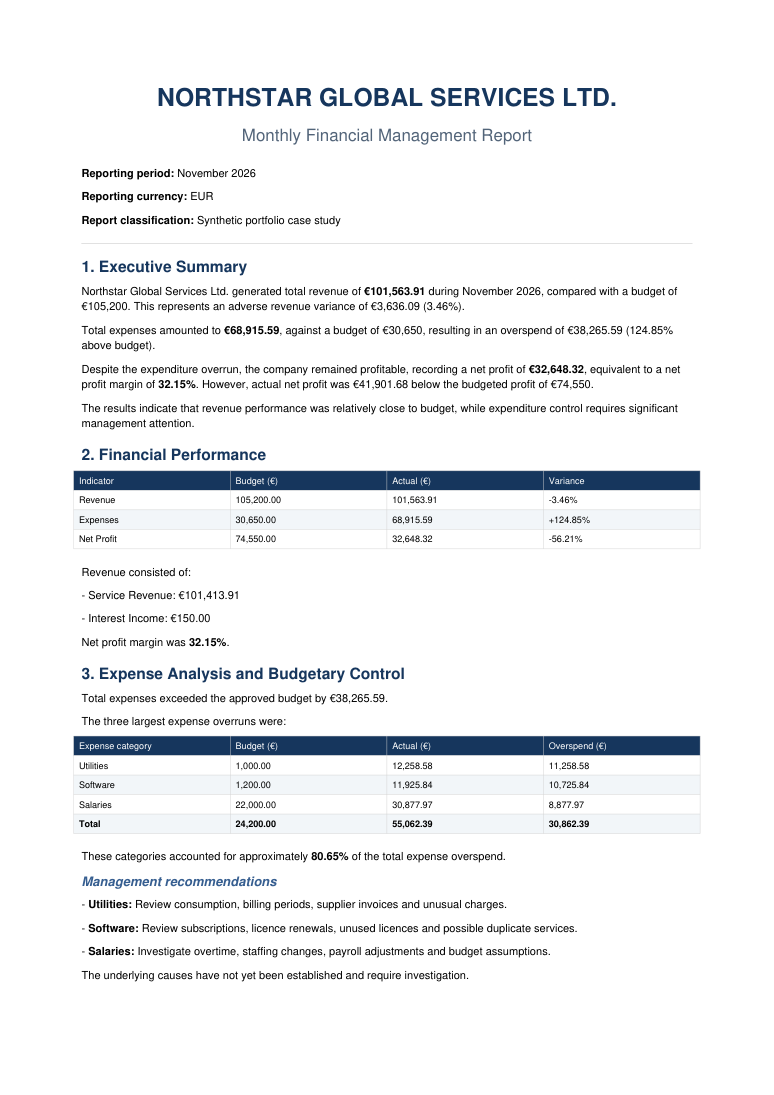

Recovered PDF — Page 2


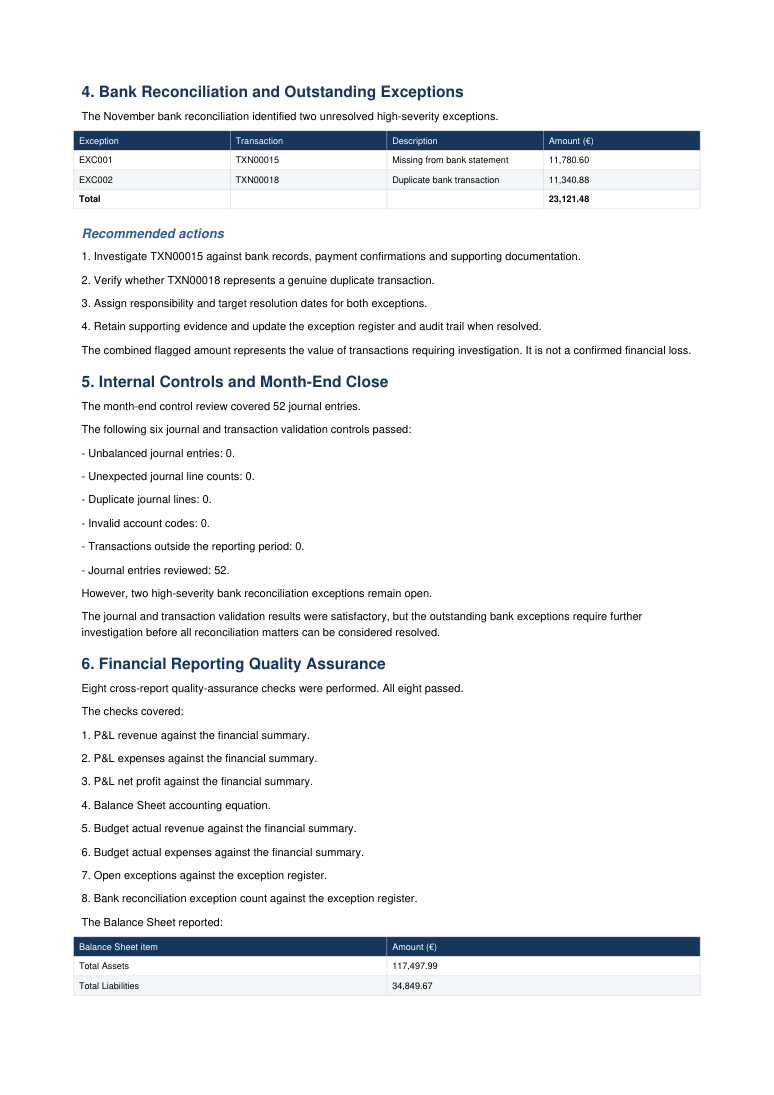

Recovered PDF — Page 3


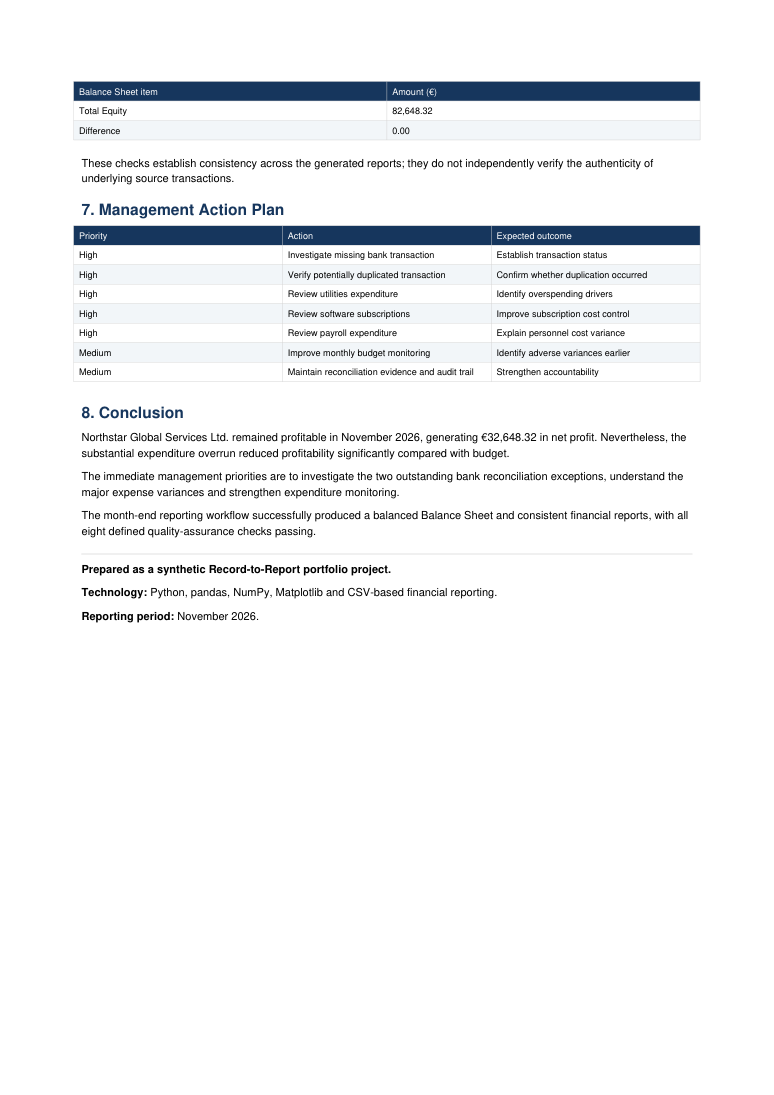

In [44]:
import fitz
from IPython.display import display, Image

recovered_doc = fitz.open(str(recovery_path))

for page_number, page in enumerate(recovered_doc):
    pix = page.get_pixmap(matrix=fitz.Matrix(1.3, 1.3))
    preview_path = REPORTS / f"recovered_preview_{page_number + 1}.png"
    pix.save(str(preview_path))

    print(f"Recovered PDF — Page {page_number + 1}")
    display(Image(filename=str(preview_path)))